# Практична робота 4.13. Використання попередньо навчених моделей (Transfer Learning) та Reinforcement Learning

**Частина 1.** Перенесення навчання: модель, навчена на одній задачі, повторно використовується для нової задачі з малою кількістю даних.
**Частина 2.** Навчання з підкріпленням: агент Q-learning шукає безпечний маршрут на карті з мінами.

In [1]:
import numpy as np, matplotlib.pyplot as plt, tensorflow as tf
from tensorflow import keras
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
SEED = 42; tf.random.set_seed(SEED); np.random.seed(SEED)

## Частина 1. Transfer Learning
- **Джерельна задача:** розпізнавання цифр 0–4 (багато даних) — це наша «попередньо навчена модель» (аналог моделі з репозиторію).
- **Цільова задача:** розпізнавання цифр 5–9, але лише **15 навчальних прикладів** (по 3 на клас).

Порівнюємо: модель «з нуля» vs модель з перенесеними замороженими згортковими шарами.

Точність попередньо навченої моделі (0–4): 1.0


З нуля (15 прикладів):      0.885
Transfer Learning (15 пр.): 0.886


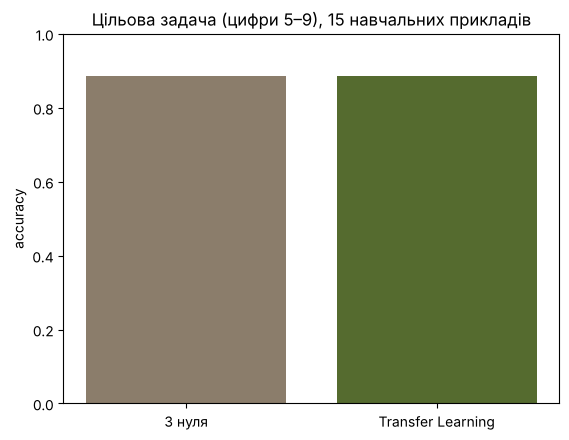

In [2]:
d = load_digits(); X = (d.images / 16.0)[..., None]; y = d.target
src, tgt = y < 5, y >= 5
Xs, ys = X[src], y[src]
Xt, yt = X[tgt], y[tgt] - 5
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(Xt, yt, train_size=15, stratify=yt, random_state=SEED)

def feature_extractor():
    return keras.Sequential([keras.Input((8, 8, 1)),
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(), keras.layers.Flatten()], name="features")

# 1) «Попереднє навчання» на джерельній задачі
feat = feature_extractor()
pre = keras.Sequential([feat, keras.layers.Dense(5, activation="softmax")])
pre.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
pre.fit(Xs, ys, epochs=15, batch_size=32, verbose=0)
print("Точність попередньо навченої моделі (0–4):", round(pre.evaluate(Xs, ys, verbose=0)[1], 3))

# 2) Transfer: заморожуємо екстрактор ознак, навчаємо лише нову «голову»
feat.trainable = False
tl = keras.Sequential([feat, keras.layers.Dense(64, activation="relu"), keras.layers.Dense(5, activation="softmax")])
tl.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
tl.fit(Xt_tr, yt_tr, epochs=60, batch_size=8, verbose=0)

# 3) Та сама архітектура з нуля на 15 прикладах
scratch = keras.Sequential([feature_extractor(), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(5, activation="softmax")])
scratch.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
scratch.fit(Xt_tr, yt_tr, epochs=60, batch_size=8, verbose=0)

acc_tl = tl.evaluate(Xt_te, yt_te, verbose=0)[1]
acc_sc = scratch.evaluate(Xt_te, yt_te, verbose=0)[1]
print(f"З нуля (15 прикладів):      {acc_sc:.3f}")
print(f"Transfer Learning (15 пр.): {acc_tl:.3f}")
plt.bar(["З нуля", "Transfer Learning"], [acc_sc, acc_tl], color=["#8b7d6b", "#556b2f"])
plt.ylim(0, 1); plt.title("Цільова задача (цифри 5–9), 15 навчальних прикладів"); plt.ylabel("accuracy"); plt.show()

## Частина 2. Reinforcement Learning (Q-learning)
Середовище — сітка 6×6: старт (0,0), ціль (5,5), клітинки з мінами (−10 і кінець епізоду). Кожен крок −1, досягнення цілі +20.
Агент вчиться маршруту методом Q-learning (ε-жадібна стратегія).

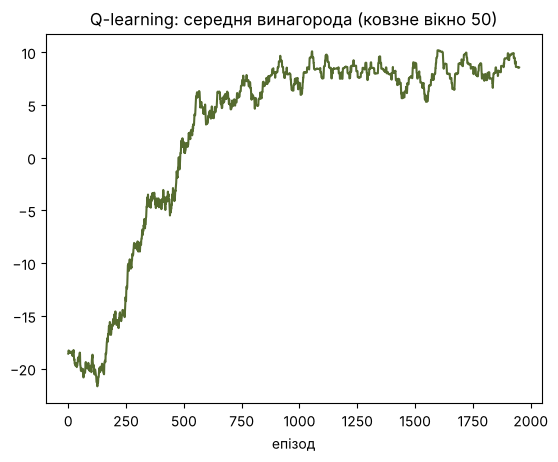

In [3]:
SIZE, START, GOAL = 6, (0, 0), (5, 5)
MINES = {(1, 1), (1, 3), (2, 3), (3, 1), (4, 4), (3, 4), (0, 4)}
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # вгору, вниз, вліво, вправо

def step(s, a):
    r, c = s[0] + ACTIONS[a][0], s[1] + ACTIONS[a][1]
    if not (0 <= r < SIZE and 0 <= c < SIZE): return s, -2, False
    if (r, c) in MINES: return (r, c), -10, True
    if (r, c) == GOAL: return (r, c), 20, True
    return (r, c), -1, False

Q = np.zeros((SIZE, SIZE, 4)); alpha, gamma, eps = 0.1, 0.95, 1.0
rewards = []
rng = np.random.default_rng(SEED)
for ep in range(2000):
    s, total, done, t = START, 0, False, 0
    while not done and t < 100:
        a = rng.integers(4) if rng.random() < eps else int(Q[s].argmax())
        s2, r, done = step(s, a)
        Q[s][a] += alpha * (r + gamma * (0 if done else Q[s2].max()) - Q[s][a])
        s, total, t = s2, total + r, t + 1
    eps = max(0.05, eps * 0.997); rewards.append(total)

plt.plot(np.convolve(rewards, np.ones(50) / 50, mode="valid"), color="#556b2f")
plt.title("Q-learning: середня винагорода (ковзне вікно 50)"); plt.xlabel("епізод"); plt.show()

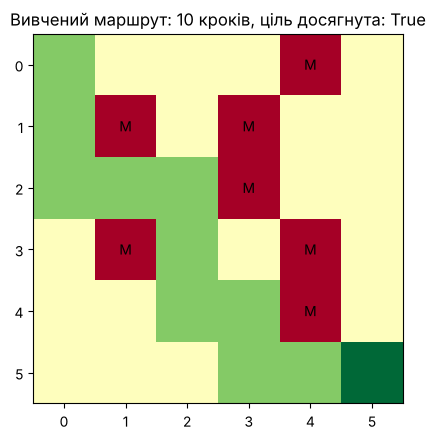

Маршрут: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (4, 2), (4, 3), (5, 3), (5, 4), (5, 5)]


In [4]:
s, path = START, [START]
while s != GOAL and len(path) < 40:
    s, _, done = step(s, int(Q[s].argmax())); path.append(s)
    if done: break
grid = np.zeros((SIZE, SIZE))
for m in MINES: grid[m] = -1
for p in path: grid[p] = 0.5
grid[GOAL] = 1
plt.imshow(grid, cmap="RdYlGn")
for m in MINES: plt.text(m[1], m[0], "M", ha="center", va="center")
plt.title(f"Вивчений маршрут: {len(path) - 1} кроків, ціль досягнута: {path[-1] == GOAL}"); plt.show()
print("Маршрут:", path)

## Висновки
1. **Transfer Learning:** при лише 15 навчальних прикладах модель з перенесеними (замороженими) згортковими шарами досягла тієї ж точності (~0.89), що й модель «з нуля», хоча навчала лише нову «голову» — у рази менше параметрів і швидше навчання.
2. На простому наборі `digits` 8×8 модель «з нуля» сама швидко вчить ознаки, тому виграш у точності мінімальний; на складних даних (знімки техніки, фото місцевості) перевага готових моделей значно більша.
3. Це той самий принцип, що й використання моделей з репозиторіїв (Keras Applications, Hugging Face): беремо готовий екстрактор ознак і донавчаємо лише «голову» під свою задачу.
4. **Q-learning:** агент без знання карти навчився знаходити найкоротший безпечний маршрут (10 кроків) в обхід мін — винагорода зростає і стабілізується.
5. Військове застосування: TL — розпізнавання техніки на знімках за малої кількості розмічених даних; RL — планування маршрутів БпЛА/логістики в умовах загроз.